In [1]:
from pathlib import Path
import pickle
import matplotlib.gridspec as gridspec
import matplotlib.font_manager as fm
import matplotlib as mpl
import matplotlib.pyplot as plt
import cmcrameri.cm as cm

In [2]:

%matplotlib inline
plt.rc('font',family='arial')
plt.rcParams.update({"font.size":6})
font= fm.FontProperties(family='arial')
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
# cmcrameri.cm.show_cmaps()
mpl._mathtext.SHRINK_FACTOR = 0.666

In [3]:


# data_dir = Path(
#     "/Volumes/University_stuff/Code_Projects/MSGI/plotting/"
#     "Publication_figures/data/IF_development"
# )

# with (data_dir / "IF_development_figure_data.pkl").open("rb") as file:
#     figure_data = pickle.load(file)

# observational_datasets = figure_data["observational_datasets"]
# model_datasets = figure_data["model_datasets"]

# config = figure_data["configuration"]

# timesteps = config["timesteps"]
# x = config["x"]
# x_labels = config["x_labels"]
# ice_phase_thresh = config["ice_phase_thresh"]

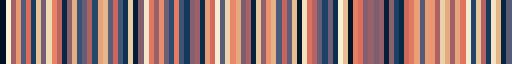

In [4]:
cm.lipariS

In [5]:
colormap=cm.lipariS.colors
color_dd=colormap[2]
color_sev=colormap[3]
color_mod=colormap[0]

In [ ]:
from pathlib import Path
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.ticker import (
    FixedLocator,
    FixedFormatter,
    MultipleLocator,
    PercentFormatter,
)


# ------------------------------------------------------------------
# Load plotted data
# ------------------------------------------------------------------

data_file = Path(
    "/Volumes/University_stuff/Code_Projects/MSGI/plotting/"
    "Publication_figures/data/IF_development/"
    "IF_development_figure_data.pkl"
)

with data_file.open("rb") as file:
    figure_data = pickle.load(file)

loaded_observations = figure_data["observational_datasets"]
loaded_models = figure_data["model_datasets"]
observational_datasets = figure_data["observational_datasets"]
model_datasets = figure_data["model_datasets"]
configuration = figure_data["configuration"]

timesteps = configuration["timesteps"]
x = np.asarray(configuration["x"])
# x_labels = ['$t_{\\mathrm{peak}}$\n$-30\\,\\mathrm{min}$',
#             '$t_{\\mathrm{peak}}$\n$-15\\,\\mathrm{min}$',
#             '$t_{\\mathrm{peak}}$',
#             '$t_{\\mathrm{peak}}$\n$+15\\,\\mathrm{min}$',
#             '$t_{\\mathrm{peak}}$\n$+30\\,\\mathrm{min}$']
x_labels = [r'-30',
            r'-15',
            r'$\mathrm{{t_{peak}}}$',
            r'+15',
            r'+30']
ice_phase_thresh = configuration["ice_phase_thresh"]


/var/folders/ps/bdhslmwj4t16q5_v16j9hwmc0000gt/T/ipykernel_54309/2605559091.py:25: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  figure_data = pickle.load(file)


In [7]:
# ------------------------------------------------------------------
# Plot styling
# ------------------------------------------------------------------

colormap = cm.lipariS.colors

color_dd = colormap[2]
color_sev = colormap[3]
color_mod = colormap[0]

PLOT_STYLE = {
    "figure": {
        "figsize": (5.501, 4.2),
        "constrained_layout": True,
    },

    "datasets": {
        "DARDAR": {
            "color": color_dd,
            "marker": "o",
        },
        "SEVIRI": {
            "color": color_sev,
            "marker": "o",
        },
        "MODIS": {
            "color": color_mod,
            "marker": "^",
        },
        "ICON instant WBF": {
            "color": colormap[4],
            "marker": "D",
        },
        "ICON rate-limited WBF": {
            "color": colormap[0],
            "marker": "D",
        },
        "CESM calibrated": {
            "color": "tab:green",
            "marker": "v",
        },
        "CESM OOTB": {
            "color": "tab:blue",
            "marker": "v",
        },
    },

    "median_line": {
        # "linestyle": ":",
        "linewidth": 2,
        "markersize": 4.5,
        "markeredgewidth": 1,
        "zorder": 3,
    },

    "fraction_line": {
        # "linestyle": "-",
        "linewidth": 2,
        "markersize": 4.5,
        "markeredgewidth": 1,
        "zorder": 3,
    },

    "confidence_band": {
        "alpha": 0.18,
        "linewidth": 0,
        "zorder": 1,
    },

    "axes": {
        "xlim_padding": 0.2,
        "ylim": (0, 1),
        "ytick_interval": 0.2,
        "tick_labelsize": 8,
    },

    "grid": {
        "axis": "y",
        "linestyle": "--",
        "linewidth": 0.7,
        "alpha": 0.35,
    },

    "legend": {
        "frameon": True,
    },
    # "Satellite R 150 km": {"color": colormap[5],
    #                        "display_name": "PAVI R 150 km"},
    "Satellite R 15 km": {"color": colormap[3],
                           "display_name": "PAVI"},
    "ICON 160 km instant WBF": {"color": colormap[4],
                                "display_name": "ICON instant WBF"},
    "ICON 160 km rate-limited WBF": {"color": colormap[0],
                                "display_name": "ICON rate-limited WBF"},
    "CESM 1 deg OOTB": {"color": colormap[5]},
    "CESM 1 deg Calibrated": {"color": colormap[6]},
    
}
classifiacation_palette = cm.lipariS.colors


MODEL_COLOR = classifiacation_palette[0]
OBS_COLOR = color_sev

MODEL_MARKER = "D"
OBS_MARKER = "o"

In [8]:
# ------------------------------------------------------------------
# Combine loaded data with current styling
# ------------------------------------------------------------------

def apply_dataset_styles(loaded_datasets, style):
    """Replace saved appearance settings while retaining loaded statistics."""

    styled_datasets = {}

    for name, loaded_config in loaded_datasets.items():
        if name not in style["datasets"]:
            raise KeyError(
                f"No styling is defined for dataset {name!r}."
            )

        styled_datasets[name] = {
            "stats": loaded_config["stats"],
            **style["datasets"][name],
        }

    return styled_datasets


observational_datasets = apply_dataset_styles(
    loaded_observations,
    PLOT_STYLE,
)

model_datasets = apply_dataset_styles(
    loaded_models,
    PLOT_STYLE,
)
model_datasets = {"ICON rate-limited WBF": model_datasets['ICON rate-limited WBF'],
                  "ICON instant WBF": model_datasets['ICON instant WBF'] }

In [9]:
def plot_dataset_group(ax_med, ax_frac, datasets, x, style, linestyle):
    for name, dataset_config in datasets.items():
        stats = dataset_config["stats"]
        color = dataset_config["color"]
        marker = dataset_config["marker"]
        if name=="SEVIRI":
            name="PAVI"

        ax_med.fill_between(
            x,
            stats["median_ci_low"],
            stats["median_ci_high"],
            color=color,
            **style["confidence_band"],
        )

        ax_med.plot(
            x,
            stats["median"],
            color=color,
            marker=marker,
            label=name,
            linestyle = linestyle,
            **style["fraction_line"],
        )

        ax_frac.fill_between(
            x,
            stats["fraction_ci_low"],
            stats["fraction_ci_high"],
            color=color,
            **style["confidence_band"],
        )

        ax_frac.plot(
            x,
            stats["fraction"],
            color=color,
            marker=marker,
            label=name,
            linestyle = linestyle,
            **style["fraction_line"],
        )

In [10]:
import pandas as pd

# ------------------------------------------------------------------
# Load occurrence-rate results
# ------------------------------------------------------------------

occurrence_file = (
    "/Volumes/University_stuff/Code_Projects/MSGI/"
    "plotting/Publication_figures/data/Occurance_rate/temp_occurrence_rates.csv"
)

temp_occurrence_df = pd.read_csv(
    occurrence_file,
    index_col="Line",
)

# Convert temperature columns from strings to numbers
temp_occurrence_df.columns = temp_occurrence_df.columns.astype(float)

# Convert each row back into a named Series
temp_occurrence_results = {
    name: temp_occurrence_df.loc[name].dropna()
    for name in temp_occurrence_df.iloc[[1,0,3,2]].index
}

In [11]:
import json
def load_plot_data(data_dir):
    data_dir = Path(data_dir)

    with open(data_dir / "metadata.json", encoding="utf-8") as file:
        metadata = json.load(file)

    mean_map = heatmap = pd.read_csv(
        data_dir / "mean_reflectivity.csv"
    )
    heatmap = pd.read_csv(
        data_dir / "reflectivity_deviation_heatmap.csv"
    )

    anomaly = pd.read_csv(
        data_dir / "sedimentation_anomaly.csv"
    )

    correlation = pd.read_csv(
        data_dir / "peak_ice_fraction_correlation.csv"
    )

    return {
        "metadata": metadata,
        "mean_map": mean_map,
        "heatmap": heatmap,
        "anomaly": anomaly,
        "correlation": correlation,
    }

In [21]:
temp_occurrence_results

{'Satellite R 15 km': -36.0    0.107970
 -30.0    0.053290
 -24.0    0.029931
 -18.0    0.017446
 -12.0    0.004819
 -6.0     0.000000
 Name: Satellite R 15 km, dtype: float64,
 'Satellite R 150 km': -36.0    0.014366
 -30.0    0.011801
 -24.0    0.007769
 -18.0    0.004056
 -12.0    0.000914
 -6.0     0.000006
 Name: Satellite R 150 km, dtype: float64,
 'ICON 160 km rate-limited WBF': -36.0    0.560085
 -30.0    0.375251
 -24.0    0.211759
 -18.0    0.145245
 -12.0    0.098560
 -6.0     0.044776
 Name: ICON 160 km rate-limited WBF, dtype: float64,
 'ICON 160 km instant WBF': -36.0    0.605189
 -30.0    0.442185
 -24.0    0.292990
 -18.0    0.243837
 -12.0    0.211535
 -6.0     0.182138
 Name: ICON 160 km instant WBF, dtype: float64}

In [ ]:
import numpy as np

def crossing_time(obs_corr, side, threshold=0.1):
    df = (
        obs_corr.loc[
            side * obs_corr["rel_time_min"] >= 0,
            ["rel_time_min", "corr_with_peak"],
        ]
        .dropna()
        .sort_values("rel_time_min", ascending=(side > 0))
    )

    t = df["rel_time_min"].to_numpy()
    magnitude = np.abs(df["corr_with_peak"].to_numpy())

    # First downward crossing as we move away from time zero
    crossings = np.flatnonzero(
        (magnitude[:-1] >= threshold) &
        (magnitude[1:] <= threshold)
    )
    if not len(crossings):
        return np.nan

    i = crossings[0]
    if magnitude[i] == threshold:
        return float(t[i])

    fraction = (threshold - magnitude[i]) / (magnitude[i + 1] - magnitude[i])
    return float(t[i] + fraction * (t[i + 1] - t[i]))

negative_time = crossing_time(obs_corr, side=-1)
positive_time = crossing_time(obs_corr, side=1)

print(f"Negative side obs: {negative_time:.2f} min")
print(f"Positive side obs: {positive_time:.2f} min")

Negative side: -49.28 min
Positive side: 40.85 min


In [31]:
negative_time = crossing_time(model_corr, side=-1)
positive_time = crossing_time(model_corr, side=1)

print(f"Negative side mod: {negative_time:.2f} min")
print(f"Positive side mod: {positive_time:.2f} min")

Negative side mod: -42.54 min
Positive side mod: 58.08 min


In [ ]:
obs_corr.interpolate()

,rel_time_min,corr_with_peak,ci_low,ci_high
0,-120,-0.045333,-0.050407,-0.040449
1,-105,-0.023465,-0.028369,-0.019104
2,-90,0.003411,-0.001878,0.007911
3,-75,0.036599,0.031798,0.040474
4,-60,0.069449,0.065280,0.072961
5,-45,0.112179,0.107647,0.115964
6,-30,0.154007,0.149817,0.158023
7,-15,0.302989,0.299130,0.307376
8,0,1.000000,1.000000,1.000000
9,15,0.407406,0.401695,0.413475


In [26]:
temp_occurrence_results["ICON 160 km instant WBF"] - temp_occurrence_results["Satellite R 15 km"]

-36.0    0.497219
-30.0    0.388895
-24.0    0.263059
-18.0    0.226390
-12.0    0.206717
-6.0     0.182138
dtype: float64

In [25]:
temp_occurrence_results["ICON 160 km instant WBF"] - temp_occurrence_results["Satellite R 15 km"]

-36.0    0.497219
-30.0    0.388895
-24.0    0.263059
-18.0    0.226390
-12.0    0.206717
-6.0     0.182138
dtype: float64

In [15]:
observational_datasets["SEVIRI"]

{'stats': {'median': array([0.33777615, 0.46810237, 0.6908837 , 0.51245564, 0.41830315]),
  'median_ci_low': array([0.33608785, 0.46694494, 0.68994649, 0.51102294, 0.41649165]),
  'median_ci_high': array([0.33927598, 0.46907737, 0.6918656 , 0.51423634, 0.42039572]),
  'fraction': array([0.02843859, 0.05426814, 0.18054592, 0.08728286, 0.06084899]),
  'fraction_ci_low': array([0.02777381, 0.05346455, 0.17924087, 0.08601383, 0.05957216]),
  'fraction_ci_high': array([0.0291326 , 0.05504433, 0.18207534, 0.08865557, 0.06207873]),
  'n': array([191641, 191641, 191641, 115246,  80708])},
 'color': array([0.912931, 0.60098 , 0.450565]),
 'marker': 'o'}

In [ ]:
observational_datasets["SEVIRI"]['stats']['median']-model_datasets["ICON rate-limited WBF"]['stats']['median']

array([0.33777615, 0.46810237, 0.6908837 , 0.51245564, 0.41830315])

In [49]:
observational_datasets["DARDAR"]['stats']['fraction']

array([0.44776119, 0.50746269, 0.55769231, 0.44      , 0.53488372])

In [51]:
model_datasets["ICON rate-limited WBF"]['stats']['fraction']

array([0.11961435, 0.14581823, 0.40069418, 0.25997301, 0.20563573])

In [47]:
observational_datasets["SEVIRI"]['stats']['fraction']

array([0.02843859, 0.05426814, 0.18054592, 0.08728286, 0.06084899])

In [46]:
model_datasets["ICON rate-limited WBF"]['stats']["fraction"]

array([0.11961435, 0.14581823, 0.40069418, 0.25997301, 0.20563573])

In [40]:
model_datasets["ICON instant WBF"]['stats']['median']

array([0.18297909, 0.33038272, 0.76924298, 0.45590945, 0.31155974])

In [ ]:
observational_datasets["Ic"]['stats']['median']

In [33]:
observations

{'metadata': {'created_utc': '2026-10-16T16:12:43.190876+00:00',
  'settings': {'l2_start': 4,
   'l_depth': 7,
   'iqr_filter_y': True,
   'iqr_filter_x': True,
   'ind_range': [-3, 4],
   'rel_times_min': [-45, -30, -15, 0, 15, 30, 45],
   'timesteps': [2, 1, 0, -1, -2],
   'mean_mode': 'log',
   'confidence_level': 0.9,
   'confidence_level_percent': 90.0,
   'n_bootstrap': 5000,
   'peak_ind': 0,
   'weight_mode': 'none',
   'weight_floor': 0.0,
   'invert_weights': False,
   'equalise_index_size': False},
  'files': {'mean_reflectivity.csv': {'description': 'Radar reflectivity means.',
    'columns': {'vertical_level': 'Vertical-level label',
     'rel_time_min': 'Time relative to the glaciation peak in minutes',
     'reflectivity_dbz': 'Radar reflectivity in dBZ'}},
   'reflectivity_deviation_heatmap.csv': {'description': 'Radar reflectivity deviation from the vertical-level mean.',
    'columns': {'vertical_level': 'Vertical-level label',
     'rel_time_min': 'Time relative to 

{'color': array([0.912931, 0.60098 , 0.450565]), 'display_name': 'PAVI'}
{'color': array([0.01137 , 0.07324 , 0.148284]), 'display_name': 'ICON rate-limited WBF'}
{'color': array([0.320355, 0.358086, 0.480032]), 'display_name': 'ICON instant WBF'}


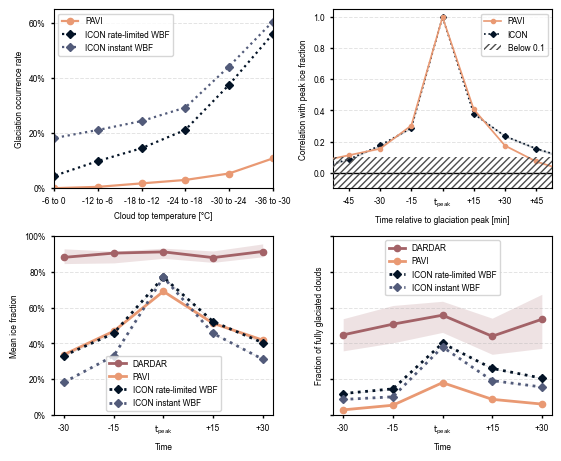

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.ticker import (
    FixedLocator,
    FixedFormatter,
    MultipleLocator,
    PercentFormatter,
)

# --------------------------------------------------------------
# Load data
# --------------------------------------------------------------
model = load_plot_data("/Volumes/University_stuff/Code_Projects/MSGI/plotting/Publication_figures/data/model")
observations = load_plot_data("/Volumes/University_stuff/Code_Projects/MSGI/plotting/Publication_figures/data/observations")
# ------------------------------------------------------------------
# Figure layout
# ------------------------------------------------------------------

fig = plt.figure(
    figsize=(5.501, 4.5),
    constrained_layout=True,
)

gs = gridspec.GridSpec(
    nrows=2,
    ncols=2,
    figure=fig,
    # height_ratios=[1, 1],
    width_ratios=[1, 1],
)

# Observations

ax_occ_rate = fig.add_subplot(
    gs[0, 0],
)
ax_memory = fig.add_subplot(
    gs[0, 1],
)
ax_med = fig.add_subplot(gs[1, 0])
ax_frac = fig.add_subplot(
    gs[1, 1],
    sharex=ax_med,
)

# ------------------------------------------------------------------
# Plot data
# ------------------------------------------------------------------

plot_dataset_group(
    ax_med=ax_med,
    ax_frac=ax_frac,
    datasets=observational_datasets,
    x=x,
    style=PLOT_STYLE,
    linestyle="-"
)

plot_dataset_group(
    ax_med=ax_med,
    ax_frac=ax_frac,
    datasets=model_datasets,
    x=x,
    style=PLOT_STYLE,
    linestyle=":"
)

# ------------------------------------------------------------------
# Titles
# ------------------------------------------------------------------

# ax_med.set_title(
#     "Median Ice Fraction",
# )

# ax_frac.set_title(
#     "Fully Glaciated Fraction\n"
#     rf"($\mathrm{{IF}} > {ice_phase_thresh:.2f}$)",
# )

# ------------------------------------------------------------------
# Explicit tick formatting
# ------------------------------------------------------------------

all_axes = [
    ax_med,
    ax_frac,
]

for ax in all_axes:
    # Horizontal axis
    ax.set_xlim(-0.2, len(x) - 0.8)
    ax.xaxis.set_major_locator(FixedLocator(x))
    ax.xaxis.set_major_formatter(FixedFormatter(x_labels))

    # Vertical axis
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_locator(MultipleLocator(0.2))
    ax.yaxis.set_major_formatter(
        PercentFormatter(
            xmax=1,
            decimals=0,
        )
    )

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.7,
        alpha=0.35,
    )

    ax.tick_params(
        axis="both",
        direction="out",
    )

# Hide x labels on the upper row
# ax_med.tick_params(
#     axis="x",
#     labelbottom=False,
# )

# ax_frac.tick_params(
#     axis="x",
#     labelbottom=False,
# )

# Hide right-column y labels while retaining aligned ticks/gridlines
ax_frac.tick_params(
    axis="y",
    labelleft=False,
)

ax_frac.tick_params(
    axis="y",
    labelleft=False,
)

# ------------------------------------------------------------------
# Axis and row labels
# ------------------------------------------------------------------

# ax_med.set_ylabel(
#     "Observations",
#     fontweight="bold",
# )

# ax_med.set_ylabel(
#     "Models",
#     fontweight="bold",
# )

ax_med.set_xlabel("Time")
ax_frac.set_xlabel("Time")

# ------------------------------------------------------------------
# Legends
# ------------------------------------------------------------------

ax_med.legend(
    loc="lower center",
    frameon=True,
)

ax_frac.legend(
    loc="upper center",
    frameon=True,
)

ax_med.legend(
    loc="lower center",
    frameon=True,
)

ax_frac.legend(
    loc="upper center",
    frameon=True,
)

ax_frac.set_ylabel("Fraction of fully glaciated clouds")
ax_med.set_ylabel("Mean ice fraction")

# ------------------------------------------------------------------
# Glaciation occurrence-rate panel
# ------------------------------------------------------------------

observation_names = [
    # "Satellite R 150 km",
    "Satellite R 15 km",
]
for name, values in temp_occurrence_results.items():
    is_observation = name in observation_names
    if name == "Satellite R 150 km":
        continue
    print(PLOT_STYLE[name])
    if name in ["CESM 1 deg Calibrated","CESM 1 deg OOTB"]:
        continue
    
    ax_occ_rate.plot(
        values.index.astype(float),
        values.to_numpy(),
        label=PLOT_STYLE[name]["display_name"],
        color=PLOT_STYLE[name]["color"],
        marker="o" if is_observation else "D",
        linestyle="-" if is_observation else ":",
        linewidth=1.6,
        markersize=4.5,
    )

# Temperature axis
temperatures = np.asarray(
    next(iter(temp_occurrence_results.values())).index,
    dtype=float,
)

ax_occ_rate.set_xlim(temperatures.min(), temperatures.max())
ax_occ_rate.invert_xaxis()

ax_occ_rate.xaxis.set_major_locator(FixedLocator(temperatures))
ax_occ_rate.xaxis.set_major_formatter(
    FixedFormatter([
        f"{temperature:g} to {temperature + 6:g}"
        for temperature in temperatures
    ])
)

ax_occ_rate.set_xlabel("Cloud top temperature [°C]")
ax_occ_rate.set_ylabel("Glaciation occurrence rate")

# Scale the y-axis to the occurrence-rate data
maximum_rate = max(
    np.nanmax(values.to_numpy())
    for values in temp_occurrence_results.values()
)

y_step = 0.2
y_max = np.ceil(maximum_rate / y_step) * y_step

ax_occ_rate.set_ylim(0, 0.65)
ax_occ_rate.yaxis.set_major_locator(MultipleLocator(y_step))
ax_occ_rate.yaxis.set_major_formatter(
    PercentFormatter(xmax=1, decimals=0)
)

ax_occ_rate.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.35,
)

ax_memory.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.35,
)

ax_occ_rate.tick_params(
    axis="both",
    direction="out",
)

ax_occ_rate.legend(
    loc="upper left",
    frameon=True,
    # fontsize=7,
    ncol=1,
)


# ------------------------------------------------------------------
# Correlation / memory panel
# ------------------------------------------------------------------

model_corr = (
    model["correlation"]
    .sort_values("rel_time_min")
    .reset_index(drop=True)
)

obs_corr = (
    observations["correlation"]
    .sort_values("rel_time_min")
    .reset_index(drop=True)
)

# Observations
ax_memory.fill_between(
    obs_corr["rel_time_min"],
    obs_corr["ci_low"],
    obs_corr["ci_high"],
    color=OBS_COLOR,
    alpha=0.20,
    linewidth=0,
    zorder=2,
)

ax_memory.plot(
    obs_corr["rel_time_min"],
    obs_corr["corr_with_peak"],
    color=OBS_COLOR,
    marker=OBS_MARKER,
    markersize=3,
    linewidth=1.2,
    linestyle="-",
    label="PAVI",
    zorder=4,
)

# Model
ax_memory.fill_between(
    model_corr["rel_time_min"],
    model_corr["ci_low"],
    model_corr["ci_high"],
    color=MODEL_COLOR,
    alpha=0.20,
    linewidth=0,
    zorder=1,
)

ax_memory.plot(
    model_corr["rel_time_min"],
    model_corr["corr_with_peak"],
    color=MODEL_COLOR,
    marker=MODEL_MARKER,
    markersize=3,
    linewidth=1.2,
    linestyle=":",
    label="ICON",
    zorder=3,
)

# Reference lines and low-correlation region
ax_memory.axhline(
    0,
    color="black",
    linewidth=1,
    zorder=5,
)

ax_memory.axhspan(
    -0.1,
    0.1,
    facecolor="none",
    edgecolor="0.3",
    hatch="/////",
    linewidth=0,
    label=r"Below 0.1",
    zorder=5,
)

# Axis formatting
all_corr_times = np.concatenate([
    model_corr["rel_time_min"].to_numpy(),
    obs_corr["rel_time_min"].to_numpy(),
])

corr_xmin = np.nanmin(all_corr_times)
corr_xmax = np.nanmax(all_corr_times)

corr_xticks = np.arange(
    np.floor(corr_xmin / 15) * 15,
    np.ceil(corr_xmax / 15) * 15 + 15,
    15,
)

corr_xlabels = [
    r"$\mathrm{{t_{peak}}}$" if np.isclose(tick, 0)
    else f"{tick:+g}"
    for tick in corr_xticks
]

ax_memory.set_xticks(corr_xticks)
ax_memory.set_xticklabels(corr_xlabels)
ax_memory.set_xlim(-52.5, 52.5)
ax_memory.set_ylim(-0.1, 1.05)

ax_memory.set_xlabel("Time relative to glaciation peak [min]")
ax_memory.set_ylabel("Correlation with peak ice fraction")

ax_memory.legend(
    loc="upper right",
    frameon=True,
)

ax_memory.tick_params(
    axis="both",
    direction="out",
)

# Make ticks lines smaller
for ax in (
    ax_occ_rate,
    ax_med,
    ax_frac,
    ax_memory):
    ax.tick_params(
        axis="both",
        which="major",
        length=2.5,      # tick-line length
        width=1,     # tick-line thickness
    )

fig.savefig(
            "/Volumes/University_stuff/Code_Projects/MSGI/plotting/Publication_figures/Multisatellite_IF_v2.pdf",
            dpi=300,
            bbox_inches="tight",
        )